# Model Interpretability and Business Insights

## Credit Risk Analytics — Predicting Credit Card Default

This notebook independently reconstructs the selected Random Forest model from Notebook 04 and interprets its predictions. Feature importance is descriptive and does not establish causation; predicted risk is not confirmed default.

## Section 1 — Introduction and Objectives

Interpretability matters in credit-risk work because stakeholders need to understand model-used information, risk scores, and error trade-offs. This notebook reconstructs the selected model, measures held-out performance, estimates descriptive feature importance, analyzes probabilities and risk segments, and translates results into cautious business insights.

## Section 2 — Environment and Dataset Setup

The path logic supports execution from the repository root or the `notebooks` directory. The workbook's first row contains the actual UCI column names and is promoted to the header. Category standardization matches Notebooks 03 and 04.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
CURRENT_DIRECTORY = Path.cwd()
PROJECT_ROOT = CURRENT_DIRECTORY.parent if CURRENT_DIRECTORY.name.lower() == "notebooks" else CURRENT_DIRECTORY
DATA_PATH = PROJECT_ROOT / "data" / "default of credit card clients.xls"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

In [15]:
df_raw = pd.read_excel(DATA_PATH)
df = df_raw.copy()
df.columns = df.iloc[0].astype(str).str.strip()
df = df.iloc[1:].reset_index(drop=True).apply(pd.to_numeric)
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Target distribution (%):")
print(df["default payment next month"].value_counts(normalize=True).sort_index().mul(100).round(2))

Dataset shape: (30000, 25)
Missing values: 0
Duplicate rows: 0
Target distribution (%):
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


## Section 3 — Feature and Target Preparation

`ID` is excluded because it is an identifier. The feature groups and transformations reproduce the earlier modeling contract. The split is stratified with `random_state=42`; preprocessing is fitted only on training data.

In [16]:
nominal_features = ["SEX", "EDUCATION", "MARRIAGE"]
repayment_features = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
billing_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]
amount_columns = billing_columns + payment_columns
demographic_features = ["AGE"]
financial_features = ["LIMIT_BAL"]
categorical_features = nominal_features + repayment_features
feature_columns = nominal_features + repayment_features + financial_features + amount_columns + demographic_features
target_column = "default payment next month"
required_columns = feature_columns + [target_column, "ID"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")
X = df[feature_columns].copy()
y = df[target_column].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Predictor count:", len(feature_columns))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training target percentages:")
print(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))
print("Testing target percentages:")
print(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))

Predictor count: 23
Training shape: (24000, 23)
Testing shape: (6000, 23)
Training target percentages:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64
Testing target percentages:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


In [17]:
categorical_pipeline = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore"))])
standard_numeric_pipeline = Pipeline(steps=[("scaler", StandardScaler())])
amount_pipeline = Pipeline(steps=[("power_transform", PowerTransformer(method="yeo-johnson", standardize=False)), ("scaler", StandardScaler())])
preprocessor = ColumnTransformer(transformers=[("categorical", categorical_pipeline, categorical_features), ("standard_numeric", standard_numeric_pipeline, demographic_features + financial_features), ("amounts", amount_pipeline, amount_columns)], remainder="drop")
print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## Section 4 — Reconstructing the Final Random Forest Model

The exact Notebook 04 configuration is used. The selected probability threshold is applied after training, and metrics are recalculated rather than assumed.

In [18]:
random_forest_model = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1))])
random_forest_model.fit(X_train, y_train)
y_test_probability = random_forest_model.predict_proba(X_test)[:, 1]
selected_threshold = 0.55
y_test_prediction = (y_test_probability >= selected_threshold).astype(int)
test_metrics = pd.Series({"Accuracy": accuracy_score(y_test, y_test_prediction), "Precision": precision_score(y_test, y_test_prediction, zero_division=0), "Recall": recall_score(y_test, y_test_prediction, zero_division=0), "F1-score": f1_score(y_test, y_test_prediction, zero_division=0), "ROC-AUC": roc_auc_score(y_test, y_test_probability)})
print("Recalculated test metrics at threshold 0.55:")
display(test_metrics.to_frame("Score").round(4))
print("Confusion matrix:")
display(pd.DataFrame(confusion_matrix(y_test, y_test_prediction), index=["Actual No Default", "Actual Default"], columns=["Predicted No Default", "Predicted Default"]))
print("Classification report:")
print(classification_report(y_test, y_test_prediction, target_names=["No Default", "Default"], zero_division=0))

Recalculated test metrics at threshold 0.55:


,Score
Accuracy,0.8015
Precision,0.5532
Recall,0.5328
F1-score,0.5428
ROC-AUC,0.7762


Confusion matrix:


,Predicted No Default,Predicted Default
Actual No Default,4102,571
Actual Default,620,707


Classification report:
              precision    recall  f1-score   support

  No Default       0.87      0.88      0.87      4673
     Default       0.55      0.53      0.54      1327

    accuracy                           0.80      6000
   macro avg       0.71      0.71      0.71      6000
weighted avg       0.80      0.80      0.80      6000



In [19]:
reference_metrics = pd.Series({"Accuracy": 0.8015, "Precision": 0.5532, "Recall": 0.5328, "F1-score": 0.5428, "ROC-AUC": 0.7762})
reference_confusion_matrix = np.array([[4102, 571], [620, 707]])
comparison = pd.DataFrame({"Recalculated": test_metrics, "Notebook 04 reference": reference_metrics})
comparison["Difference"] = comparison["Recalculated"] - comparison["Notebook 04 reference"]
print("Reference comparison:")
display(comparison.round(4))
print("Confusion-matrix difference (recalculated minus reference):")
display(pd.DataFrame(confusion_matrix(y_test, y_test_prediction) - reference_confusion_matrix, index=["Actual No Default", "Actual Default"], columns=["Predicted No Default", "Predicted Default"]))

Reference comparison:


,Recalculated,Notebook 04 reference,Difference
Accuracy,0.8015,0.8015,0.0
Precision,0.5532,0.5532,0.0
Recall,0.5328,0.5328,-0.0
F1-score,0.5428,0.5428,0.0
ROC-AUC,0.7762,0.7762,0.0


Confusion-matrix difference (recalculated minus reference):


,Predicted No Default,Predicted Default
Actual No Default,0,0
Actual Default,0,0


## Section 5 — Permutation Feature Importance

Permutation importance measures the decrease in held-out F1-score after shuffling one original input feature. It is descriptive interpretation only, not model selection. It does not show causation or relationship direction. Correlated features can share predictive information. Impurity-based importance is shown for comparison, but may be biased by feature type and cardinality.

Top 20 original input features by held-out permutation importance:


,Feature,Mean F1 decrease,Std F1 decrease
0,PAY_0,0.08215,0.00463
1,PAY_2,0.02087,0.00276
2,PAY_AMT2,0.00874,0.00521
3,PAY_AMT3,0.00829,0.00525
4,PAY_AMT1,0.00747,0.00635
5,BILL_AMT1,0.00665,0.00328
6,PAY_AMT4,0.00518,0.00207
7,PAY_3,0.00479,0.00302
8,BILL_AMT5,0.00462,0.00253
9,PAY_4,0.00248,0.00239


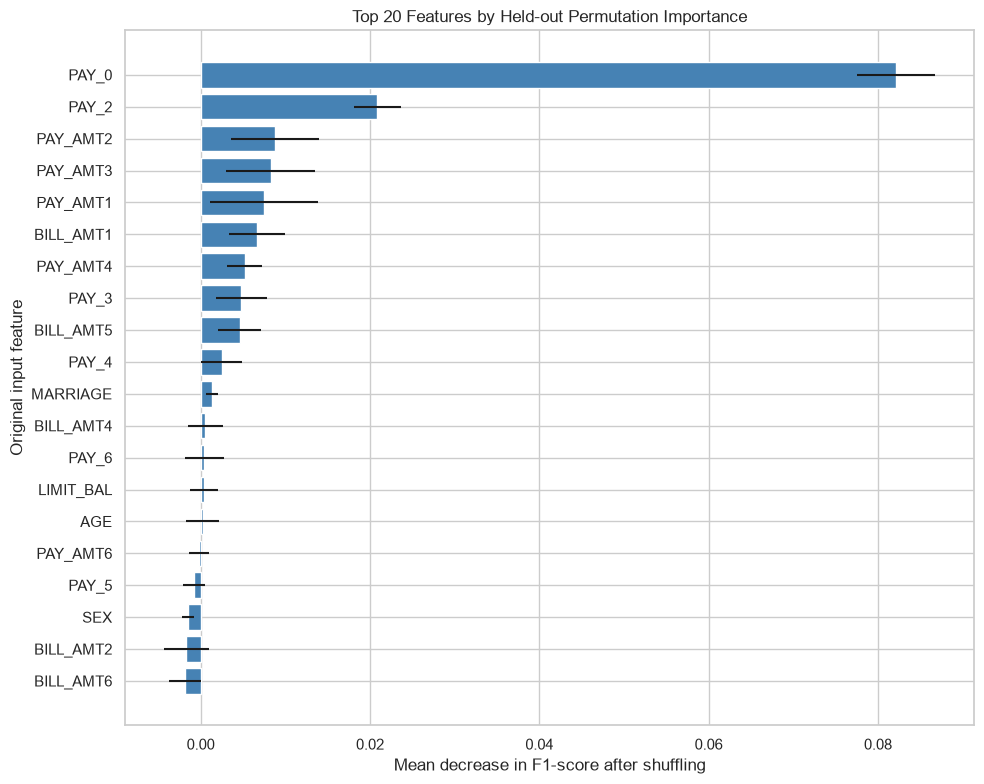

In [20]:
permutation_result = permutation_importance(random_forest_model, X_test, y_test, scoring="f1", n_repeats=5, random_state=42, n_jobs=-1)
permutation_importance_table = pd.DataFrame({"Feature": X_test.columns, "Mean F1 decrease": permutation_result.importances_mean, "Std F1 decrease": permutation_result.importances_std}).sort_values("Mean F1 decrease", ascending=False).reset_index(drop=True)
print("Top 20 original input features by held-out permutation importance:")
display(permutation_importance_table.head(20).round(5))
top_permutation = permutation_importance_table.head(20).sort_values("Mean F1 decrease")
plt.figure(figsize=(10, 8))
plt.barh(top_permutation["Feature"], top_permutation["Mean F1 decrease"], xerr=top_permutation["Std F1 decrease"], color="steelblue")
plt.title("Top 20 Features by Held-out Permutation Importance")
plt.xlabel("Mean decrease in F1-score after shuffling")
plt.ylabel("Original input feature")
plt.tight_layout()
plt.show()

In [21]:
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
fitted_classifier = random_forest_model.named_steps["classifier"]
transformed_feature_names = fitted_preprocessor.get_feature_names_out()
impurity_importance_table = pd.DataFrame({"Transformed feature": transformed_feature_names, "Impurity importance": fitted_classifier.feature_importances_}).sort_values("Impurity importance", ascending=False).reset_index(drop=True)
print("Top 20 transformed features by impurity-based importance:")
display(impurity_importance_table.head(20).round(5))
print("Permutation importance shuffles original columns through the pipeline; impurity importance reports transformed columns inside the forest.")

Top 20 transformed features by impurity-based importance:


,Transformed feature,Impurity importance
0,categorical__PAY_0_2,0.12125
1,categorical__PAY_2_2,0.06959
2,standard_numeric__LIMIT_BAL,0.04854
3,amounts__PAY_AMT1,0.04839
4,categorical__PAY_3_2,0.04424
5,categorical__PAY_0_0,0.04369
6,amounts__BILL_AMT1,0.04106
7,amounts__PAY_AMT2,0.04095
8,amounts__PAY_AMT3,0.03765
9,amounts__BILL_AMT2,0.03618


Permutation importance shuffles original columns through the pipeline; impurity importance reports transformed columns inside the forest.


## Section 6 — Credit Risk Probability Analysis

The model probability is an estimated score and has not been assumed to be calibrated. Threshold 0.55 converts the continuous score into a class prediction; changing it changes the precision/recall trade-off.

Predicted probability summary:


,Predicted default probability
count,6000.0000
mean,0.4087
std,0.2036
min,0.0908
25%,0.2554
50%,0.3545
75%,0.5045
max,0.9721


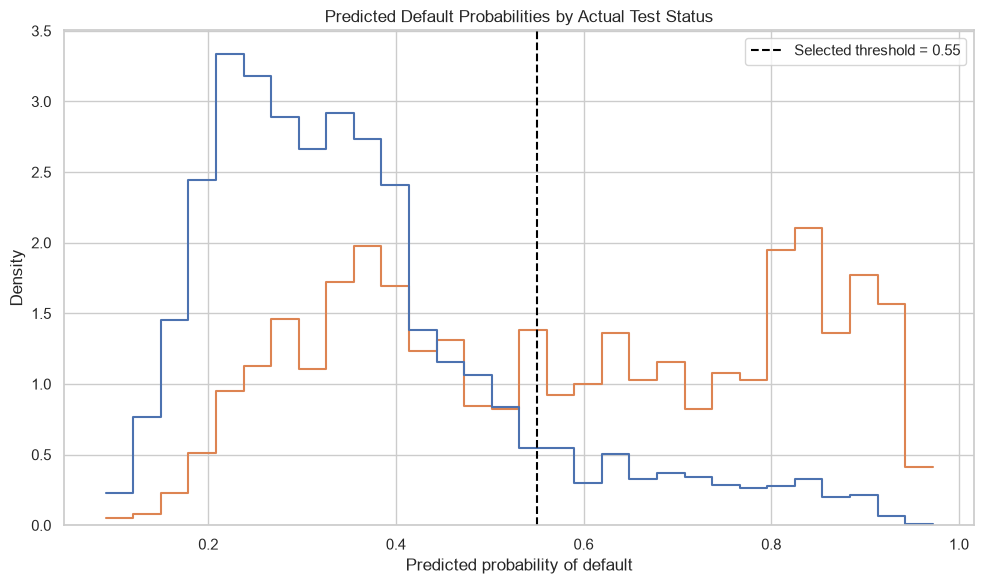

Predicted class counts at threshold 0.55:


,Customers
Predicted no default,4722
Predicted default,1278


In [22]:
probability_summary = pd.Series(y_test_probability).describe()
print("Predicted probability summary:")
display(probability_summary.to_frame("Predicted default probability").round(4))
probability_plot_data = pd.DataFrame({"Predicted probability": y_test_probability, "Actual status": np.where(y_test.to_numpy() == 1, "Actual default", "Actual no default")})
plt.figure(figsize=(10, 6))
sns.histplot(data=probability_plot_data, x="Predicted probability", hue="Actual status", bins=30, stat="density", common_norm=False, element="step", fill=False)
plt.axvline(selected_threshold, color="black", linestyle="--", label="Selected threshold = 0.55")
plt.title("Predicted Default Probabilities by Actual Test Status")
plt.xlabel("Predicted probability of default")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()
print("Predicted class counts at threshold 0.55:")
display(pd.Series(y_test_prediction).value_counts().sort_index().rename(index={0: "Predicted no default", 1: "Predicted default"}).to_frame("Customers"))

## Section 7 — Customer Risk Segmentation

Illustrative boundaries are used: low predicted risk is below 0.25, medium is 0.25 to below 0.50, and high is at least 0.50. These are analytical assumptions, not universal banking standards. Segment labels describe estimated risk; actual default rates are calculated afterward from held-out labels.

Risk-segment summary:


,Customers,Actual_defaults,Actual_default_rate,Average_predicted_probability,Customer_percentage
Risk segment,,,,,
Low predicted risk,1407,81,5.7569,0.2013,23.45
Medium predicted risk,3066,474,15.4599,0.3548,51.10
High predicted risk,1527,772,50.5566,0.7082,25.45


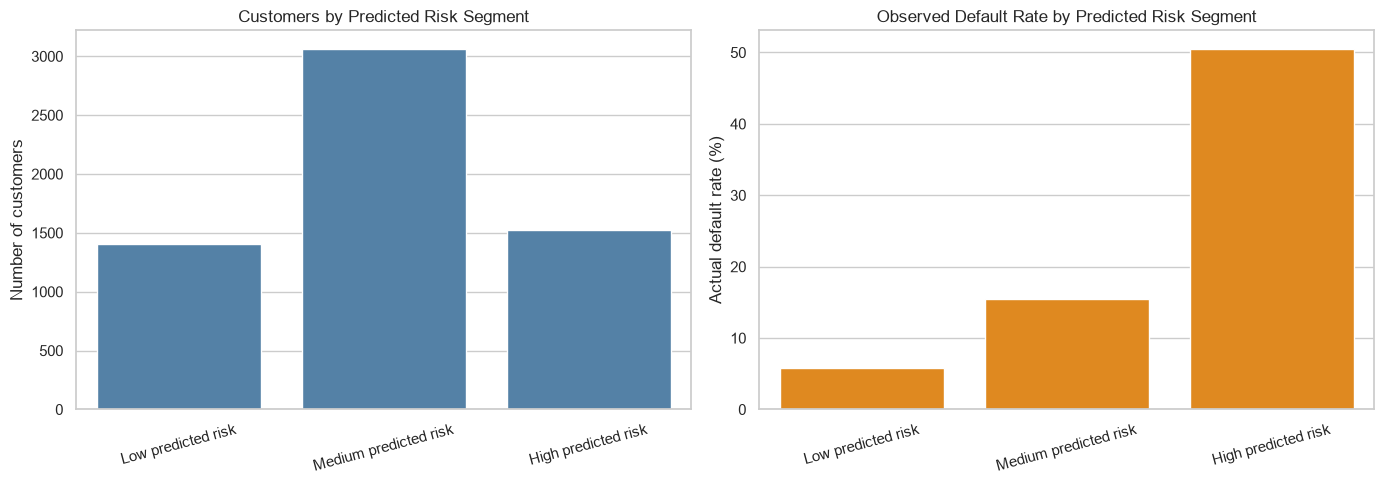

In [23]:
risk_bins = [-np.inf, 0.25, 0.50, np.inf]
risk_labels = ["Low predicted risk", "Medium predicted risk", "High predicted risk"]
risk_analysis = pd.DataFrame({"Predicted probability": y_test_probability, "Actual default": y_test.to_numpy()})
risk_analysis["Risk segment"] = pd.cut(risk_analysis["Predicted probability"], bins=risk_bins, labels=risk_labels, right=False)
segment_summary = risk_analysis.groupby("Risk segment", observed=False).agg(Customers=("Actual default", "size"), Actual_defaults=("Actual default", "sum"), Actual_default_rate=("Actual default", "mean"), Average_predicted_probability=("Predicted probability", "mean")).reindex(risk_labels)
segment_summary["Customer_percentage"] = segment_summary["Customers"] / len(risk_analysis) * 100
segment_summary["Actual_default_rate"] *= 100
print("Risk-segment summary:")
display(segment_summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=segment_summary.reset_index(), x="Risk segment", y="Customers", ax=axes[0], color="steelblue")
axes[0].set_title("Customers by Predicted Risk Segment")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of customers")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=segment_summary.reset_index(), x="Risk segment", y="Actual_default_rate", ax=axes[1], color="darkorange")
axes[1].set_title("Observed Default Rate by Predicted Risk Segment")
axes[1].set_xlabel("")
axes[1].set_ylabel("Actual default rate (%)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## Section 8 — Business Insights and Recommendations

- Repayment-history variables are relevant candidates for risk monitoring because they describe recent payment status and are available to the model. Importance does not prove that delayed payment causes future default.
- Credit limits, billing amounts, and payment amounts provide account-size and payment-behaviour context. Financial variables may be correlated and should be interpreted jointly.
- Risk segments can support prioritization: lower-risk groups may receive routine monitoring, while higher predicted-risk groups may receive additional review or customer-support attention.
- Institutions could use model outputs to prioritize manual review, but should not use this research model as an automatic approval or rejection rule without governance, validation, calibration, fairness assessment, and domain-defined error costs.

## Section 9 — Model Limitations

- The historical dataset represents credit-card clients from Taiwan; results may not generalize to current portfolios, products, or other regions.
- Defaults are the minority class, so accuracy alone is insufficient; precision, recall, F1-score, ROC-AUC, and the confusion matrix should be considered together.
- False positives and false negatives have different customer and business costs that are not available here.
- This is a single train/test experiment; temporal, external, and repeated validation are needed before deployment.
- Predicted probabilities have not been calibrated or evaluated with calibration curves or a calibration score.
- Demographic variables are present, but subgroup performance and fairness have not been comprehensively evaluated.
- Feature importance is sample- and model-dependent; correlated predictors can redistribute importance, and neither importance method establishes causation or relationship direction.
- A production system would also require governance, privacy review, regulatory compliance, drift monitoring, documentation, and human oversight.

## Section 10 — Final Conclusion

This notebook independently reconstructs the selected Random Forest, measures performance at the established threshold, and provides descriptive interpretation through held-out permutation importance, probability distributions, and illustrative risk segments. The practical recommendation is to use these outputs for research-oriented monitoring and manual-review prioritization rather than automatic customer decisions. Future work should evaluate calibration, subgroup fairness, temporal and external validation, cost-sensitive thresholds, monitoring, and a documented production inference process.

In [24]:
print("Final execution summary")
print(test_metrics.round(4).to_string())
print("Top five permutation-importance features:", ", ".join(permutation_importance_table.head(5)["Feature"].tolist()))
print("Risk segments evaluated:", ", ".join(risk_labels))
print("Interpretation is descriptive and does not establish causation or calibration.")

Final execution summary
Accuracy     0.8015
Precision    0.5532
Recall       0.5328
F1-score     0.5428
ROC-AUC      0.7762
Top five permutation-importance features: PAY_0, PAY_2, PAY_AMT2, PAY_AMT3, PAY_AMT1
Risk segments evaluated: Low predicted risk, Medium predicted risk, High predicted risk
Interpretation is descriptive and does not establish causation or calibration.
